<a href="https://colab.research.google.com/github/ayandeshmukh75-hue/Sales-Prediction-using-Python/blob/main/Sales_Prediction_using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Remove unnecessary index column
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving Advertising.csv to Advertising (1).csv
Dataset loaded successfully!
Dataset shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Column Names:
['TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [4]:
df_clean = df.copy()

# Convert columns to numeric values
for col in ["TV", "Radio", "Newspaper", "Sales"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Remove missing values and duplicates
df_clean = df_clean.dropna().drop_duplicates().reset_index(drop=True)

print("Data cleaning completed!")
print("Records after cleaning:", len(df_clean))
print("\nMissing values:")
print(df_clean.isnull().sum())

Data cleaning completed!
Records after cleaning: 200

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


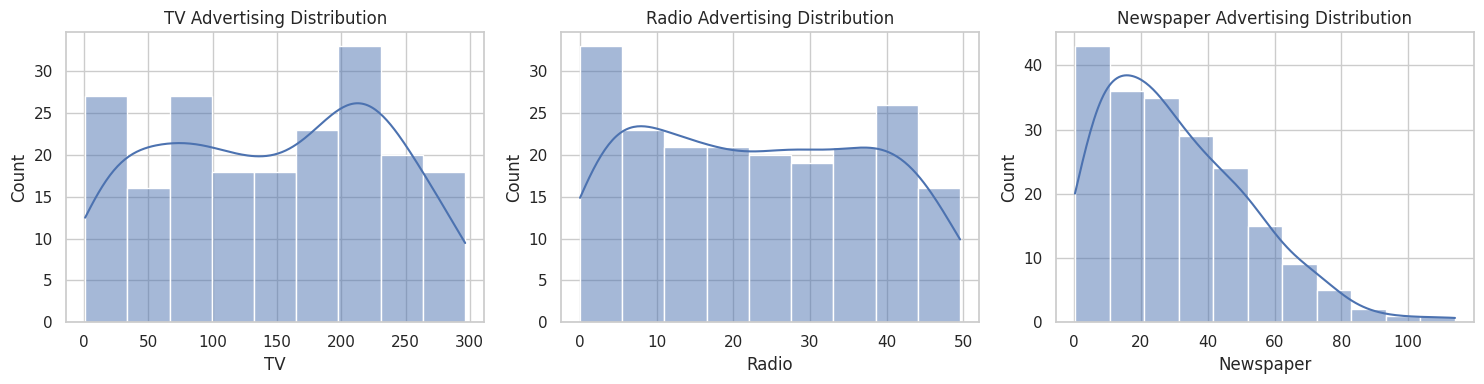

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.histplot(data=df_clean, x=col, kde=True, ax=ax)
    ax.set_title(f"{col} Advertising Distribution")

plt.tight_layout()
plt.savefig("advertising_distribution.png", dpi=300)
plt.show()

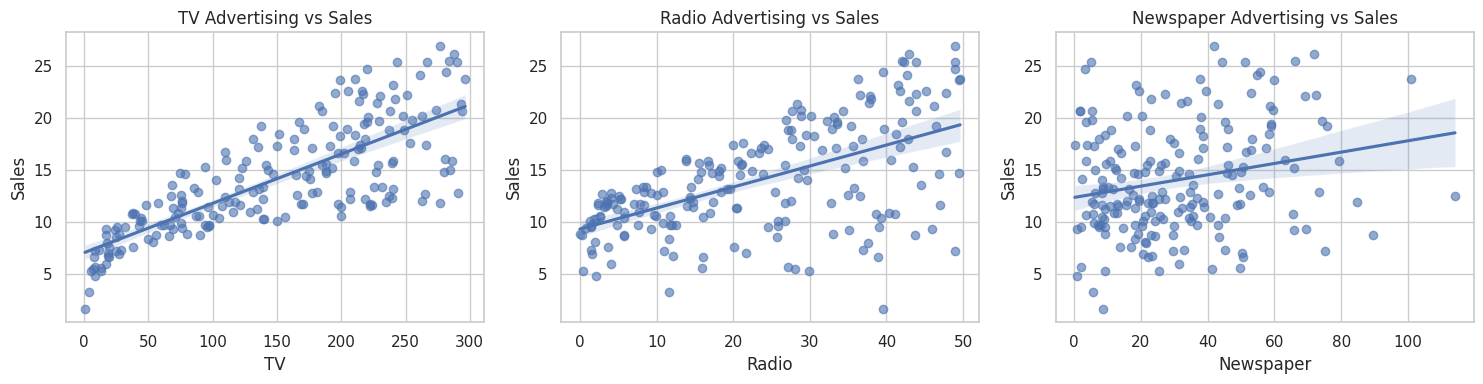

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(
        data=df_clean,
        x=col,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.6}
    )
    ax.set_title(f"{col} Advertising vs Sales")

plt.tight_layout()
plt.savefig("advertising_vs_sales.png", dpi=300)
plt.show()

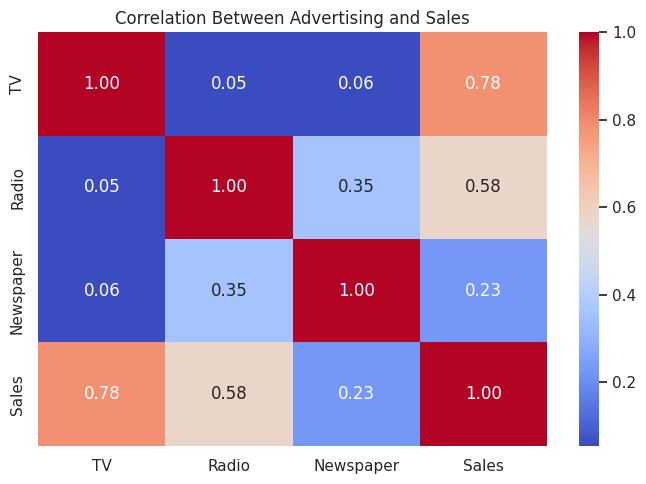

In [7]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df_clean.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Advertising and Sales")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

In [8]:
X = df_clean[["TV", "Radio", "Newspaper"]]
y = df_clean["Sales"]

print("Input features:", X.columns.tolist())
print("Target variable: Sales")
print("Total records:", len(df_clean))

Input features: ['TV', 'Radio', 'Newspaper']
Target variable: Sales
Total records: 200


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [10]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

print("\nModel Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print("Intercept:", round(model.intercept_, 4))

Linear Regression model trained successfully!

Model Coefficients:
TV: 0.0447
Radio: 0.1892
Newspaper: 0.0028
Intercept: 2.9791


In [11]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 30)
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R² Score: {r2:.3f}")

MODEL EVALUATION
------------------------------
MAE: 1.461
RMSE: 1.782
R² Score: 0.899


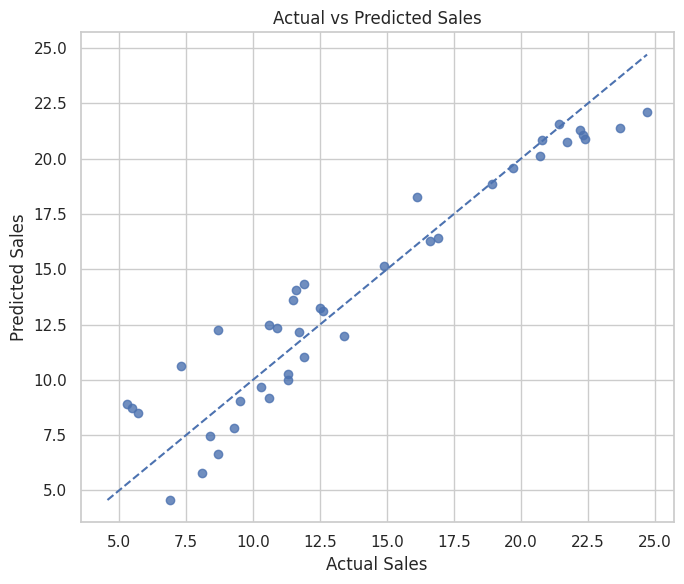

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.8)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot(
    [low, high],
    [low, high],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.tight_layout()
plt.savefig("actual_vs_predicted_sales.png", dpi=300)
plt.show()

In [13]:
new_advertising = pd.DataFrame([{
    "TV": 200,
    "Radio": 30,
    "Newspaper": 40
}])

predicted_sales = model.predict(new_advertising)[0]

print("New Advertising Details:")
display(new_advertising)

print(f"Predicted Sales: {predicted_sales:.2f}")

New Advertising Details:


,TV,Radio,Newspaper
0,200,30,40


Predicted Sales: 17.71
